In [5]:
# 1. Import libraries
import requests
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
# 2. Enter API details
#bef93c07436473891c2014dc0b03c48d
API_KEY = "YOUR_API_KEY_HERE"
CITY = "Pune"

In [7]:
# 3. Fetch weather data from API
url = "https://api.openweathermap.org/data/2.5/forecast"

params = {
    'q': CITY,
    'appid': API_KEY,
    'units': 'metric'
}

response = requests.get(url, params=params)
data = response.json()

In [8]:
# 4. Check API response
if response.status_code != 200:
    raise RuntimeError(f"API request failed with status {response.status_code}: {data.get('message')}")

records = []
for item in data['list']:
    records.append({
        'Date': item['dt_txt'],
        'Temperature': item['main']['temp'],
        'Humidity': item['main']['humidity'],
        'Wind_Speed': item['wind']['speed'],
        'Precipitation': item.get('rain', {}).get('3h', 0)
    })

In [9]:
# 6. Clean and preprocess data
df = pd.DataFrame(records)
df['Date'] = pd.to_datetime(df['Date'])
df = df.drop_duplicates()
df = df.fillna(0)
print(df.head())


                 Date  Temperature  Humidity  Wind_Speed  Precipitation
0 2026-11-02 12:00:00        24.20        67        0.58           0.00
1 2026-11-02 15:00:00        23.02        74        0.35           0.16
2 2026-11-02 18:00:00        21.85        80        1.02           0.64
3 2026-11-02 21:00:00        21.37        83        0.82           0.70
4 2026-11-03 00:00:00        20.98        83        0.39           0.00


In [10]:
# 7. Calculate weather statistics
print("Average Temperature:", df['Temperature'].mean())
print("Maximum Temperature:", df['Temperature'].max())
print("Minimum Temperature:", df['Temperature'].min())


Average Temperature: 26.04975
Maximum Temperature: 31.29
Minimum Temperature: 20.98


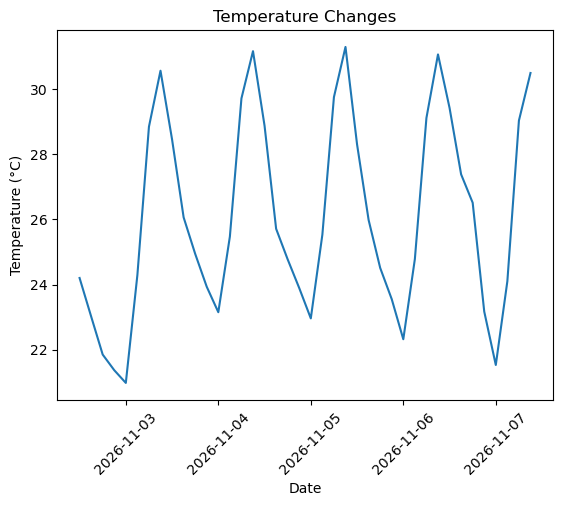

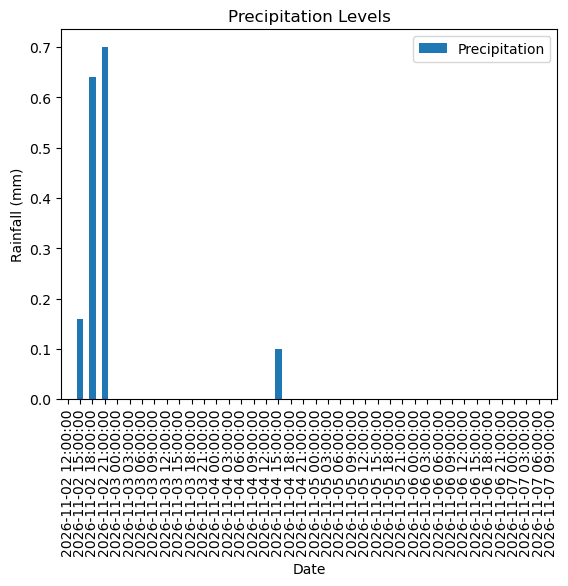

In [11]:
# 8. Visualize temperature changes
plt.plot(df['Date'], df['Temperature'])
plt.title("Temperature Changes")
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")
plt.xticks(rotation=45)
plt.show()

# 9. Visualize precipitation
df.plot(x='Date', y='Precipitation', kind='bar')
plt.title("Precipitation Levels")
plt.ylabel("Rainfall (mm)")
plt.show()

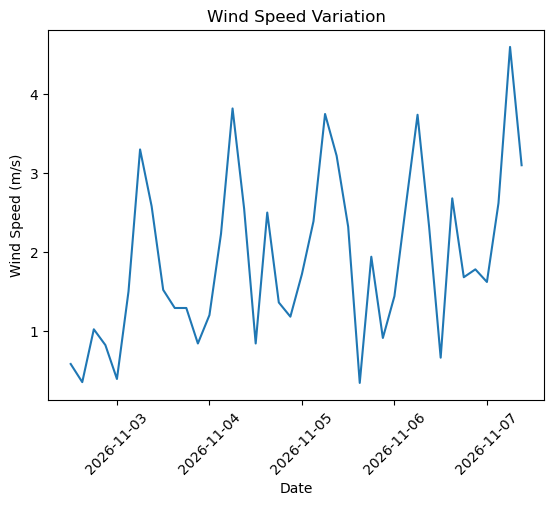

Daily Weather Summary:
            Temperature  Humidity  Wind_Speed  Precipitation
Date                                                        
2026-11-02     22.61000    76.000     0.69250            1.5
2026-11-03     26.00625    62.375     1.58875            0.0
2026-11-04     26.59125    58.375     1.96000            0.1
2026-11-05     26.48375    53.875     2.07375            0.0
2026-11-06     26.71875    44.000     2.11250            0.0
2026-11-07     26.28750    35.000     2.98500            0.0


In [12]:
# 10. Visualize wind speed
plt.plot(df['Date'], df['Wind_Speed'])
plt.title("Wind Speed Variation")
plt.xlabel("Date")
plt.ylabel("Wind Speed (m/s)")
plt.xticks(rotation=45)
plt.show()

# 11. Daily aggregation
daily = df.groupby(df['Date'].dt.date).agg({
    'Temperature': 'mean',
    'Humidity': 'mean',
    'Wind_Speed': 'mean',
    'Precipitation': 'sum'
})

print("Daily Weather Summary:")
print(daily)

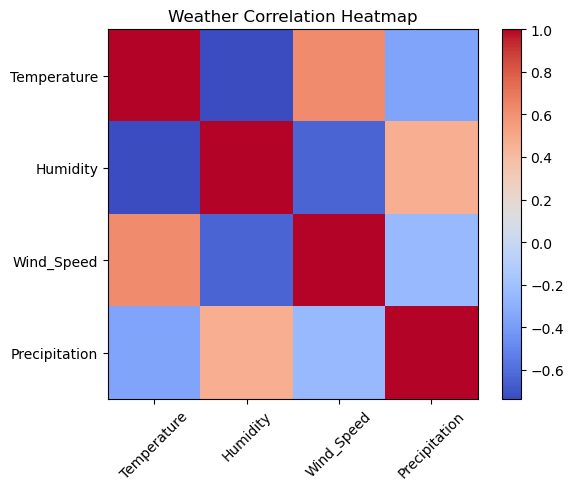

In [13]:
# 12. Correlation heatmap
corr = df[['Temperature', 'Humidity',
            'Wind_Speed', 'Precipitation']].corr()

plt.imshow(corr, cmap='coolwarm')
plt.colorbar()
plt.xticks(range(4), corr.columns, rotation=45)
plt.yticks(range(4), corr.columns)
plt.title("Weather Correlation Heatmap")
plt.show()

In [14]:
# 13. Display geographical information
print("Latitude:", data['city']['coord']['lat'])
print("Longitude:", data['city']['coord']['lon'])

# 14. Save weather data
df.to_csv("Weather_Data.csv", index=False)
print("Weather data saved successfully!")

Latitude: 18.5196
Longitude: 73.8553
Weather data saved successfully!
